# Telecom Customer Churn: a walkthrough

**The business question: who is leaving, why, and what should we do about it?**

This is a shorter, simpler companion to the full churn-prediction notebook. It keeps the skills you will use almost every week in a data analyst job (checking data, exploring it, building a first prediction model, and turning that model into a business decision) and leaves out the advanced statistics.

*Dataset: [Telecom Customer Churn by Maven Analytics](https://www.kaggle.com/datasets/shilongzhuang/telecom-customer-churn-by-maven-analytics) on Kaggle: 7,043 California customers, with their status at the end of Q2 2022.*

### What you will practise

| # | Section | What you do | Skill you take away |
|---|---------|-------------|---------------------|
| 1 | Business question | Write down the target and the decision | Scoping a request |
| 2 | Load and check the data | Read the CSV, find nulls, spot two traps | Data quality |
| 3 | Clean and prepare | Fill nulls with meaning, create the target | Reusable cleaning code |
| 4 | Explore | Churn rates by segment, the hot-spot, churn reasons | Finding insights |
| 5 | Predict | Baseline, logistic regression, gradient boosting, the right metrics | Modelling basics |
| 6 | Explain | What drives the predictions | Explaining a model |
| 7 | Decide | Turn probabilities into money and a call list | Business impact |
| 8 | Summarise | Findings, recommendations, limitations | Reporting |

### Before you start

1. Python 3.10 or newer, and `pip install pandas numpy scikit-learn matplotlib seaborn jupyter`
2. Download `telecom_customer_churn.csv` from the Kaggle link above and put it in a folder called `data/` next to this notebook.
3. Run the cells from top to bottom (**Shift + Enter**). The whole notebook runs in under a minute.

### How each section is laid out

**Goal** (what and why) → code → **What to notice** (how to read the output). Some sections add a **Pitfall**: a mistake this step protects you from.

> **Left out on purpose** (all covered in the full notebook): survival analysis, significance tests, hyperparameter tuning, calibration, fairness checks, customer clustering, and the zip-code table.

## 1. The business question

Good analysis starts before the first line of code. Write down what decision your work supports.

| Question | Answer for this project |
|---|---|
| **Decision** | Which customers should the retention team contact, and what should the company fix? |
| **Who is in the data?** | All 7,043 customers who were active at some point during the quarter |
| **What is "churn"?** | `Customer Status == "Churned"` → **1**. `Stayed` or `Joined` → **0** |
| **How do we judge a model?** | Does it put the real churners near the top of the list? And does acting on it make money? |
| **What can we *not* say?** | This is one snapshot in time. We can say *who* churns, but we cannot *prove why* |

> **Pitfall:** jumping straight to "build a model" before agreeing on who is in the population, what counts as churn, and what action the prediction will trigger.

## 2. Load and check the data

**Goal:** get the data in safely and find problems *before* they reach a chart or a model.

### 2.1 Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

SEED = 42                      # makes random steps repeatable: you get the same results every run
np.random.seed(SEED)

# One consistent look for all charts
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False})
RED, BLUE, GREY = "#D1495B", "#2E86AB", "#8D99AE"
pd.set_option("display.max_columns", 50)

# Find the data file
DATA_DIR = next((p for p in [Path("data"), Path("."), Path("../data")] if (p / "telecom_customer_churn.csv").exists()), None)
assert DATA_DIR is not None, "Put telecom_customer_churn.csv in a folder called 'data' next to this notebook."
print("Reading data from:", DATA_DIR)

Reading data from: data


### 2.2 Read the CSV (and avoid a silent trap)

By default, pandas treats the text `"None"` as a **missing value**. In this file, `Offer = "None"` is a real answer: *the customer accepted no marketing offer*. Let's read the file two ways and compare.

In [2]:
path = DATA_DIR / "telecom_customer_churn.csv"

default_read = pd.read_csv(path)                                          # pandas default behaviour
careful_read = pd.read_csv(path, keep_default_na=False, na_values=[""])   # only EMPTY cells count as missing

print(f"'Offer' values treated as missing, default read : {default_read['Offer'].isna().sum():,}")
print(f"'Offer' values treated as missing, careful read : {careful_read['Offer'].isna().sum():,}")

raw = careful_read.copy()    # keep an untouched copy of the data exactly as loaded

'Offer' values treated as missing, default read : 3,877
'Offer' values treated as missing, careful read : 0


**What to notice:** with the default read, more than half of the customers would look like they have *no information* about their offer. Nothing would crash and no warning would appear; the data would simply be wrong. Whenever a column contains words like `"None"`, `"NA"` or `"N/A"`, check how your tool reads them.

### 2.3 First look

In [3]:
df = raw.copy()
# snake_case names are shorter and safer to type: "Avg Monthly GB Download" -> "avg_monthly_gb_download"
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

print("Rows, columns:", df.shape)
df.head(3).T      # .T flips the table so all 38 columns fit on screen

Rows, columns: (7043, 38)


,0,1,2
customer_id,0002-ORFBO,0003-MKNFE,0004-TLHLJ
gender,Female,Male,Male
age,37,46,50
married,Yes,No,No
number_of_dependents,0,0,0
city,Frazier Park,Glendale,Costa Mesa
zip_code,93225,91206,92627
latitude,34.827662,34.162515,33.645672
longitude,-118.999073,-118.203869,-117.922613
number_of_referrals,2,0,0


### 2.4 Three quick quality questions

Ask these of **every** new dataset: *Are there duplicates? Where are the nulls? Are any values impossible?*

In [4]:
# 1) Duplicates: one row per customer?
print(f"Rows: {len(df):,} | unique customer IDs: {df['customer_id'].nunique():,}")

# 2) Nulls: how many, and in which columns?
missing = df.isna().sum()
missing = missing[missing > 0]
pd.DataFrame({"missing": missing, "share_%": (missing / len(df) * 100).round(1)})

Rows: 7,043 | unique customer IDs: 7,043


,missing,share_%
avg_monthly_long_distance_charges,682,9.7
multiple_lines,682,9.7
internet_type,1526,21.7
avg_monthly_gb_download,1526,21.7
online_security,1526,21.7
online_backup,1526,21.7
device_protection_plan,1526,21.7
premium_tech_support,1526,21.7
streaming_tv,1526,21.7
streaming_movies,1526,21.7


Many columns share the same count (1,526 or 682). That is a clue that these nulls are not random. Let's test the idea that **a null means "this does not apply to the customer"**.

In [5]:
no_internet = df["internet_service"] == "No"
no_phone = df["phone_service"] == "No"
churned = df["customer_status"] == "Churned"

print("Internet details are empty ONLY for customers without internet :", (df["internet_type"].isna() == no_internet).all())
print("Phone details are empty ONLY for customers without phone       :", (df["multiple_lines"].isna() == no_phone).all())
print("Churn reason is filled ONLY for customers who churned          :", (df["churn_reason"].notna() == churned).all())

Internet details are empty ONLY for customers without internet : True
Phone details are empty ONLY for customers without phone       : True
Churn reason is filled ONLY for customers who churned          : True


**Decision:** every null here is **structural** (the field does not apply). Nothing was lost, so we do **not** fill with a mean or median. Averaging the download volume of customers *without internet* would invent usage that does not exist. In Section 3 we give each null an explicit meaning instead (`"No internet"`, `0 GB`).

> **Pitfall:** automatically filling nulls with the average. First ask *why* the value is missing.

Now, impossible or extreme values:

In [6]:
# 3) Odd values: look at the ranges of the main numeric columns
display(df[["age", "tenure_in_months", "monthly_charge", "avg_monthly_gb_download", "total_revenue"]].describe().round(1))

negative = df[df["monthly_charge"] < 0]
print(f"\n{len(negative)} customers have a NEGATIVE monthly charge "
      f"(range {negative['monthly_charge'].min():.0f} to {negative['monthly_charge'].max():.0f}).")

,age,tenure_in_months,monthly_charge,avg_monthly_gb_download,total_revenue
count,7043.0,7043.0,7043.0,5517.0,7043.0
mean,46.5,32.4,63.6,26.2,3034.4
std,16.8,24.5,31.2,19.6,2865.2
min,19.0,1.0,-10.0,2.0,21.4
25%,32.0,9.0,30.4,13.0,605.6
50%,46.0,29.0,70.0,21.0,2108.6
75%,60.0,55.0,89.8,30.0,4801.1
max,80.0,72.0,118.8,85.0,11979.3



120 customers have a NEGATIVE monthly charge (range -10 to -1).


**What to notice:** ages and tenures are realistic. (`avg_monthly_gb_download` has fewer values than the other columns because of the nulls we just explained.) The negative monthly charges look like billing credits rather than typing errors, so we **keep** them (and floor them at 0 later when we estimate customer *value*). Many numeric columns are skewed, with a few very large values. Those are real customers with large bills, and deleting them would remove exactly the cases that are interesting.

> **Pitfall:** deleting outliers by reflex. First ask: *is this value possible in the real world?*

### 2.5 A second trap: what do we do with `Joined` customers?

`Customer Status` has three values: **Stayed**, **Churned**, and **Joined** (new customers this quarter). It is tempting to drop `Joined` ("they are too new to churn") and compare only Churned vs Stayed. Let's see what that would do.

In [7]:
print(df["customer_status"].value_counts(), "\n")
print("Shortest tenure among 'Stayed' customers:", df.loc[df["customer_status"] == "Stayed", "tenure_in_months"].min(), "months\n")

early = df[df["tenure_in_months"] <= 3]      # very new customers
print("Customers with tenure of 3 months or less:")
print(early["customer_status"].value_counts(), "\n")

rate_if_dropped = (early.loc[early["customer_status"] != "Joined", "customer_status"] == "Churned").mean()
rate_if_kept = (early["customer_status"] == "Churned").mean()
print(f"Early-tenure churn rate if we DROP 'Joined': {rate_if_dropped:.0%}")
print(f"Early-tenure churn rate if we KEEP 'Joined': {rate_if_kept:.0%}")

customer_status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64 

Shortest tenure among 'Stayed' customers: 4 months

Customers with tenure of 3 months or less:
customer_status
Churned    597
Joined     454
Name: count, dtype: int64 

Early-tenure churn rate if we DROP 'Joined': 100%
Early-tenure churn rate if we KEEP 'Joined': 57%


**What to notice:** no `Stayed` customer has fewer than 4 months of tenure, so customers with 3 months or less are either `Churned` or `Joined`. If we drop `Joined`, *every* remaining early customer is a churner, and a model would learn "tenure ≤ 3 months means churn" with total certainty. That is an artefact of how the labels were built, not a real pattern.

**Decision:** keep `Joined` customers and treat them as retained (`churn = 0`). The target is *"Churned" vs everyone else*.

> **Lesson:** always ask how a label was *constructed* before you model it.

## 3. Clean and prepare the data

**Goal:** put all cleaning in **one function**, so exactly the same steps run on today's file and on next month's new data.

> **Pitfall:** cleaning with loose, one-off cells. Months later nobody remembers which steps were applied or in what order.

In [8]:
PROTECTION = ["online_security", "online_backup", "device_protection_plan", "premium_tech_support"]
INTERNET_ONLY = PROTECTION + ["streaming_tv", "streaming_movies", "streaming_music", "unlimited_data"]

def clean(data):
    """Raw customer table -> tidy table ready for analysis and modelling."""
    d = data.copy()
    d.columns = d.columns.str.strip().str.lower().str.replace(" ", "_")   # safe to repeat

    # 1) Give every structural null an explicit meaning (instead of guessing a value)
    d["internet_type"] = d["internet_type"].fillna("No internet")
    for col in INTERNET_ONLY:
        d[col] = d[col].fillna("No internet")
    d["multiple_lines"] = d["multiple_lines"].fillna("No phone service")
    d["avg_monthly_gb_download"] = d["avg_monthly_gb_download"].fillna(0)               # no internet -> 0 GB
    d["avg_monthly_long_distance_charges"] = d["avg_monthly_long_distance_charges"].fillna(0)

    # 2) Make the text clearer
    d["offer"] = d["offer"].replace({"None": "No offer"})

    # 3) New columns (feature engineering): combine or group existing ones
    d["n_protection"] = sum((d[c] == "Yes").astype(int) for c in PROTECTION)           # how many protection add-ons?
    d["tenure_band"] = pd.cut(d["tenure_in_months"], [0, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
    d["referral_band"] = pd.cut(d["number_of_referrals"], [-1, 0, 1, 4, 11], labels=["0", "1", "2-4", "5+"])
    d["dependents_band"] = pd.cut(d["number_of_dependents"], [-1, 0, 1, 9], labels=["0", "1", "2+"])
    d["age_band"] = pd.cut(d["age"], [18, 30, 40, 50, 60, 70, 80], labels=["19-30", "31-40", "41-50", "51-60", "61-70", "71-80"])

    # 4) The target: 1 = churned, 0 = still a customer (Stayed or Joined)
    d["churn"] = (d["customer_status"] == "Churned").astype(int)
    return d

df = clean(raw)

remaining = df.isna().sum()
print("Nulls left (should only be the two churn-reason columns):", remaining[remaining > 0].to_dict())
print(f"Churn rate: {df['churn'].mean():.1%}  ({df['churn'].sum():,} of {len(df):,} customers)")

Nulls left (should only be the two churn-reason columns): {'churn_category': 5174, 'churn_reason': 5174}
Churn rate: 26.5%  (1,869 of 7,043 customers)


**What to notice:** the only nulls left are `churn_category` and `churn_reason`, which are *supposed* to be empty for customers who did not leave. About one customer in four churned, so the target is **imbalanced** (more stayers than leavers). That matters when we choose metrics in Section 5.

## 4. Explore: who churns, and why?

**Goal:** find the segments where churn is high, so the business knows where to look.

The basic move in churn analysis: because churn is coded 0/1, the **average of the column *is* the churn rate**. Group by a column, take the average, and you have the churn rate per group.

### 4.1 The big picture

In [9]:
overall = df["churn"].mean()
lost_mrr = df.loc[df["churn"] == 1, "monthly_charge"].sum()      # MRR = monthly recurring revenue
total_mrr = df["monthly_charge"].sum()

display(Markdown(f"**{overall:.1%} of customers churned** this quarter, taking **${lost_mrr:,.0f} of monthly revenue** "
                 f"with them ({lost_mrr / total_mrr:.1%} of the total)."))

df.groupby("customer_status").agg(customers=("customer_id", "size"),
                                  avg_tenure_months=("tenure_in_months", "mean"),
                                  avg_monthly_charge=("monthly_charge", "mean")).round(1)

**26.5% of customers churned** this quarter, taking **$137,087 of monthly revenue** with them (30.6% of the total).

,customers,avg_tenure_months,avg_monthly_charge
customer_status,,,
Churned,1869,18.0,73.3
Joined,454,1.7,42.8
Stayed,4720,41.0,61.7


### 4.2 Churn rate by segment

Two helper functions: one computes the churn rate and group size for any column, the other draws it. **Always show the group size (`n`)**: a 60% churn rate among 15 customers is far less trustworthy than 30% among 1,500.

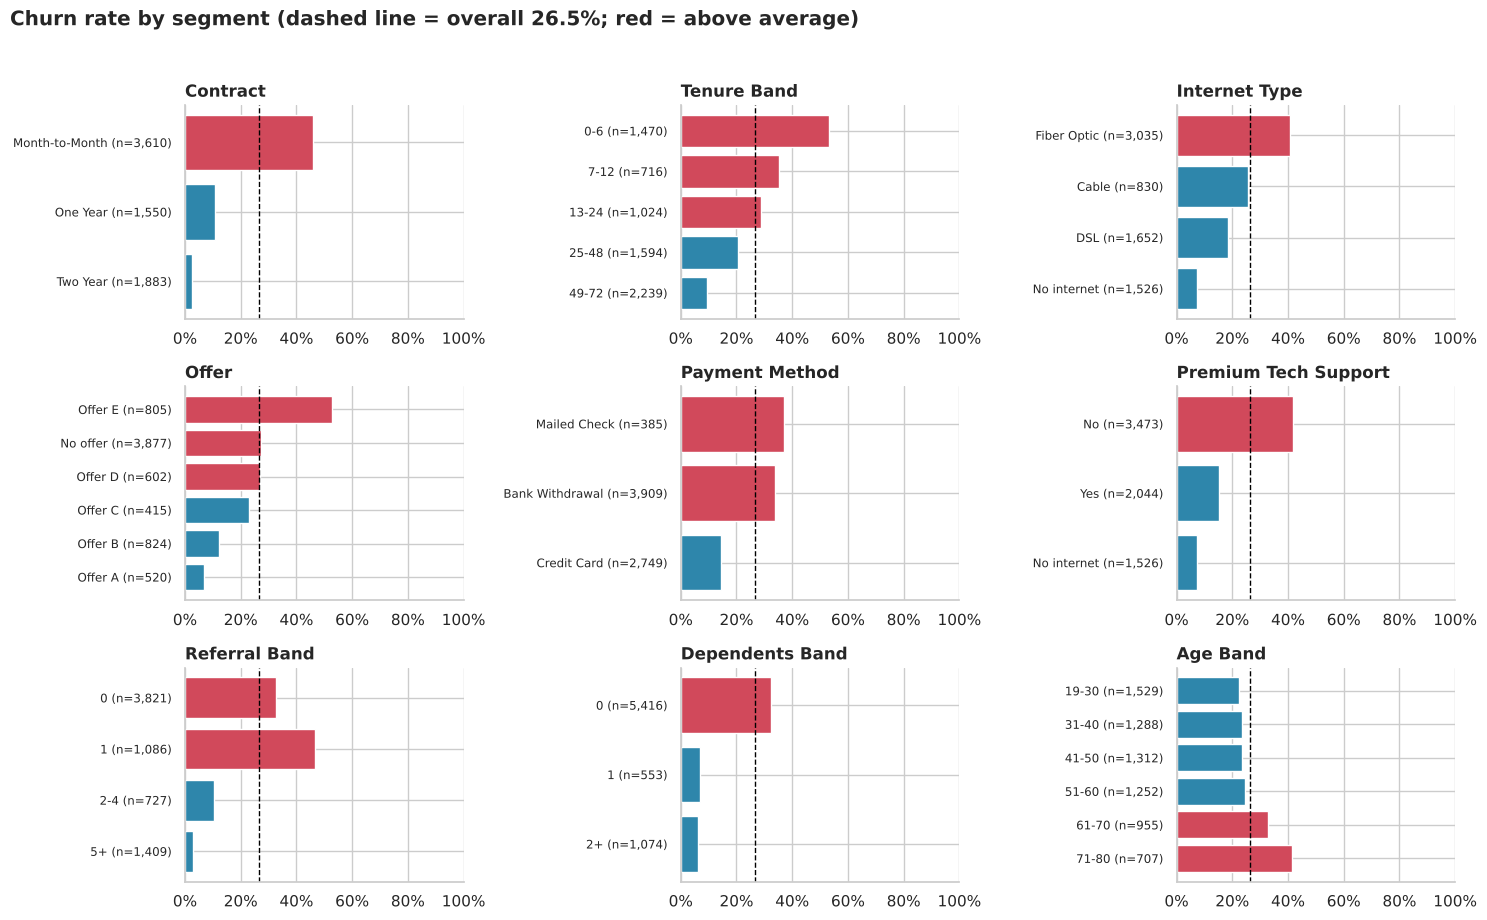

In [10]:
def churn_table(col):
    """Number of customers and churn rate for each value of `col`."""
    return df.groupby(col, observed=True)["churn"].agg(customers="size", churn_rate="mean")

def plot_churn_rates(cols, ncols=3):
    """One bar chart per column. Red bar = churn above the overall rate; dashed line = overall rate."""
    nrows = -(-len(cols) // ncols)                      # round up
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows))
    axes = np.ravel(axes)
    for ax in axes[len(cols):]:
        ax.axis("off")                                  # hide unused panels
    for ax, col in zip(axes, cols):
        t = churn_table(col)
        if not isinstance(df[col].dtype, pd.CategoricalDtype):   # text categories: sort by rate; ordered bands keep their order
            t = t.sort_values("churn_rate", ascending=False)
        ax.barh([f"{v} (n={n:,})" for v, n in zip(t.index, t.customers)], t.churn_rate,
                color=[RED if r > overall else BLUE for r in t.churn_rate])
        ax.invert_yaxis()
        ax.axvline(overall, color="black", ls="--", lw=1)
        ax.set_xlim(0, 1)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.set_title(col.replace("_", " ").title())
        ax.tick_params(axis="y", labelsize=8.5)
    fig.suptitle(f"Churn rate by segment (dashed line = overall {overall:.1%}; red = above average)",
                 x=0.01, ha="left", fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

plot_churn_rates(["contract", "tenure_band", "internet_type", "offer", "payment_method", "premium_tech_support",
                  "referral_band", "dependents_band", "age_band"])

In [11]:
rate = lambda col, val: df.loc[df[col] == val, "churn"].mean()      # churn rate of one group

display(Markdown(f"""
**What to notice**

* **Contract type is the biggest lever.** Month-to-month customers churn at **{rate('contract', 'Month-to-Month'):.0%}**, one-year at {rate('contract', 'One Year'):.0%}, two-year at only {rate('contract', 'Two Year'):.0%}.
* **The first months are the danger zone.** {rate('tenure_band', '0-6'):.0%} of customers with 6 months or less of tenure churned, against {rate('tenure_band', '49-72'):.0%} after four years.
* **Fiber optic** customers churn at {rate('internet_type', 'Fiber Optic'):.0%}, against {rate('internet_type', 'DSL'):.0%} for DSL.
* **Offer E** stands out at {rate('offer', 'Offer E'):.0%}, while Offer A is only {rate('offer', 'Offer A'):.0%}.
* **Premium tech support** (internet customers): {rate('premium_tech_support', 'No'):.0%} churn without it, {rate('premium_tech_support', 'Yes'):.0%} with it.
* **Social ties protect.** Customers with 0 referrals churn at {rate('referral_band', '0'):.0%} (1 referral: {rate('referral_band', '1'):.0%}), but those with 5 or more referrals at only {rate('referral_band', '5+'):.0%}. Customers with no dependents churn at {rate('dependents_band', '0'):.0%}, against {rate('dependents_band', '2+'):.0%} for those with 2 or more.
* **Age:** customers aged 71-80 churn at {rate('age_band', '71-80'):.0%}, against {rate('age_band', '19-30'):.0%} for those aged 19-30.

> **Association is not causation.** Customers who buy tech support differ from those who do not in many other ways. These charts tell us *where to look*; they do not prove that selling tech support *causes* people to stay. Proving that takes an experiment (an A/B test).
"""))


**What to notice**

* **Contract type is the biggest lever.** Month-to-month customers churn at **46%**, one-year at 11%, two-year at only 3%.
* **The first months are the danger zone.** 53% of customers with 6 months or less of tenure churned, against 10% after four years.
* **Fiber optic** customers churn at 41%, against 19% for DSL.
* **Offer E** stands out at 53%, while Offer A is only 7%.
* **Premium tech support** (internet customers): 42% churn without it, 15% with it.
* **Social ties protect.** Customers with 0 referrals churn at 33% (1 referral: 47%), but those with 5 or more referrals at only 3%. Customers with no dependents churn at 33%, against 6% for those with 2 or more.
* **Age:** customers aged 71-80 churn at 41%, against 22% for those aged 19-30.

> **Association is not causation.** Customers who buy tech support differ from those who do not in many other ways. These charts tell us *where to look*; they do not prove that selling tech support *causes* people to stay. Proving that takes an experiment (an A/B test).


### 4.3 Combining two factors: contract × internet type

One-dimensional charts can hide combinations. A two-way table (a **heatmap**) shows where the real hot-spot is.

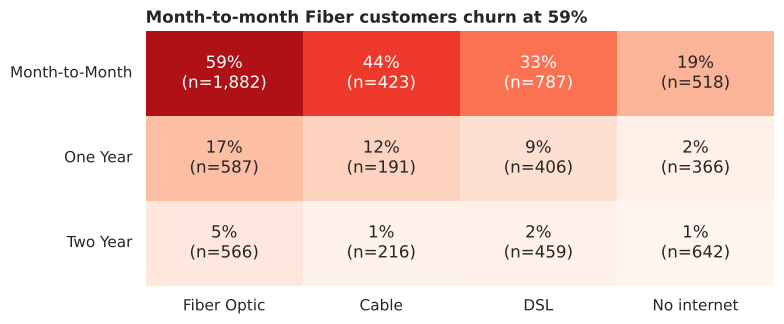

The **month-to-month + Fiber** group is **27% of customers** but **59% of all churners**. This is the first group a retention team will want to look at.

In [12]:
order_contract = ["Month-to-Month", "One Year", "Two Year"]
order_internet = ["Fiber Optic", "Cable", "DSL", "No internet"]

rates = df.pivot_table(index="contract", columns="internet_type", values="churn", aggfunc="mean").loc[order_contract, order_internet]
counts = df.pivot_table(index="contract", columns="internet_type", values="churn", aggfunc="size").loc[order_contract, order_internet]
labels = np.array([[f"{rates.iloc[i, j]:.0%}\n(n={counts.iloc[i, j]:,})" for j in range(4)] for i in range(3)])

fig, ax = plt.subplots(figsize=(8, 3.4))
sns.heatmap(rates, annot=labels, fmt="", cmap="Reds", vmin=0, vmax=0.7, cbar=False, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title(f"Month-to-month Fiber customers churn at {rates.loc['Month-to-Month', 'Fiber Optic']:.0%}")
plt.tight_layout()
plt.show()

hot = df[(df["contract"] == "Month-to-Month") & (df["internet_type"] == "Fiber Optic")]
hot_customer_share = len(hot) / len(df)
hot_churner_share = hot["churn"].sum() / df["churn"].sum()
display(Markdown(f"The **month-to-month + Fiber** group is **{hot_customer_share:.0%} of customers** but **{hot_churner_share:.0%} of all churners**. "
                 "This is the first group a retention team will want to look at."))

### 4.4 Why do they leave?

Customers who churned were asked for a reason. These reasons only exist **after** someone has left, so we use them to *diagnose* the problem here, and we will **never** use them to predict churn (that would be leakage; see Section 5).

,share_of_churners_%
churn_category,
Competitor,45.0
Dissatisfaction,17.2
Attitude,16.8
Price,11.3
Other,9.7


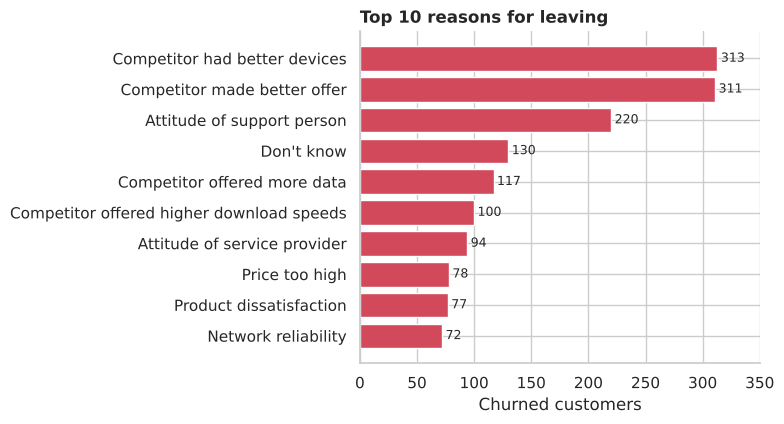

In [13]:
churners = df[df["churn"] == 1]

by_category = churners["churn_category"].value_counts(normalize=True).rename("share_of_churners").to_frame()
display((by_category * 100).round(1).rename(columns={"share_of_churners": "share_of_churners_%"}))

top_reasons = churners["churn_reason"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(top_reasons.index, top_reasons.values, color=RED)
ax.invert_yaxis()
for i, v in enumerate(top_reasons.values):
    ax.text(v + 3, i, str(v), va="center", fontsize=9)
ax.set_xlim(0, top_reasons.max() * 1.12)
ax.set_xlabel("Churned customers")
ax.set_title("Top 10 reasons for leaving")
plt.tight_layout()
plt.show()

competitor_share = by_category.loc["Competitor", "share_of_churners"]

all_reasons = churners["churn_reason"].value_counts()
support_rank = list(all_reasons.index).index("Attitude of support person") + 1
support_n = all_reasons["Attitude of support person"]

In [14]:
display(Markdown(f"""
**What to notice**

* **Competitors** account for **{competitor_share:.0%}** of churners (better devices, better offers, more data, faster speeds). This is a product and pricing question.
* **"Attitude of support person"** alone is reason number {support_rank} ({support_n} customers), and "attitude of service provider" is also in the top 10. That is a **customer-service** problem, and the cheapest one to fix because it is fully inside the company's control.
* Reasons such as *Moved* or *Deceased* cannot be addressed, so they should be left out of any estimate of "saveable" churn.
"""))


**What to notice**

* **Competitors** account for **45%** of churners (better devices, better offers, more data, faster speeds). This is a product and pricing question.
* **"Attitude of support person"** alone is reason number 3 (220 customers), and "attitude of service provider" is also in the top 10. That is a **customer-service** problem, and the cheapest one to fix because it is fully inside the company's control.
* Reasons such as *Moved* or *Deceased* cannot be addressed, so they should be left out of any estimate of "saveable" churn.


## 5. Predict: build a first churn model

**Goal:** give every customer a **churn probability** (0% to 100%), so the retention team can start with the riskiest customers.

**The plan:** (1) choose which columns the model may see, (2) split the data, (3) set a "do nothing clever" baseline, (4) fit two models, (5) judge them with the right metrics.

### 5.1 Which columns may the model see? (the leakage check)

For every column ask: ***"Would I know this value at the moment I need to make the prediction?"*** If not, it is **leakage**: the model gets to peek at the answer and looks brilliant on paper, but is useless in real life.

| Columns | Decision | Why |
|---|---|---|
| `customer_status`, `churn_category`, `churn_reason` | **Exclude** (leakage) | They only exist *after* the customer leaves |
| `customer_id`, `city`, `zip_code`, `latitude`, `longitude` | Exclude | Identifiers or too many unique values; the model would memorise noise |
| `total_charges`, `total_revenue`, `total_refunds`, `total_extra_data_charges`, `total_long_distance_charges` | Exclude | Running totals: mostly *monthly charge × tenure*, and possibly measured after the churn event |
| `internet_service` | Exclude | Says the same as `internet_type == "No internet"` |
| `gender` | Exclude | No link to churn (checked below) and an avoidable fairness risk |
| `tenure_band`, `referral_band`, `dependents_band`, `age_band` | Exclude | Made for charts only; the model uses the raw numbers |
| `age` | **Keep, with care** | Informative but sensitive: check company policy before treating customers differently by age |

In [15]:
TARGET = "churn"
LEAKY = ["customer_status", "churn_category", "churn_reason"]
NOT_USEFUL = ["customer_id", "city", "zip_code", "latitude", "longitude", "gender"]
RUNNING_TOTALS = ["total_charges", "total_revenue", "total_refunds", "total_extra_data_charges", "total_long_distance_charges"]
OTHER_EXCLUDED = ["internet_service", "tenure_band", "referral_band", "dependents_band", "age_band"]

FEATURES = [c for c in df.columns if c not in [TARGET] + LEAKY + NOT_USEFUL + RUNNING_TOTALS + OTHER_EXCLUDED]
num_cols = [c for c in FEATURES if pd.api.types.is_numeric_dtype(df[c])]
cat_cols = [c for c in FEATURES if c not in num_cols]

print(f"{len(FEATURES)} features: {len(num_cols)} numeric + {len(cat_cols)} categorical")
print("Numeric    :", num_cols)
print("Categorical:", cat_cols)

print("\nChecking the claim that gender is unrelated to churn:")
churn_table("gender")

24 features: 8 numeric + 16 categorical
Numeric    : ['age', 'number_of_dependents', 'number_of_referrals', 'tenure_in_months', 'avg_monthly_long_distance_charges', 'avg_monthly_gb_download', 'monthly_charge', 'n_protection']
Categorical: ['married', 'offer', 'phone_service', 'multiple_lines', 'internet_type', 'online_security', 'online_backup', 'device_protection_plan', 'premium_tech_support', 'streaming_tv', 'streaming_movies', 'streaming_music', 'unlimited_data', 'contract', 'paperless_billing', 'payment_method']

Checking the claim that gender is unrelated to churn:


,customers,churn_rate
gender,,
Female,3488,0.269209
Male,3555,0.261603


### 5.2 Split the data: training set and test set

Think of an exam. The **training set** is the study material, and the **test set** is the exam paper, which you only open **once** at the end. If you tune your model on the test set, your score no longer tells you how it will do on new customers. `stratify=y` keeps the same share of churners in both parts.

In [16]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Training set: {len(X_train):,} customers ({y_train.mean():.1%} churn)")
print(f"Test set    : {len(X_test):,} customers ({y_test.mean():.1%} churn)")

Training set: 5,634 customers (26.5% churn)
Test set    : 1,409 customers (26.5% churn)


### 5.3 The baseline: what if we do nothing clever?

Before building anything, check how well a model that **always predicts "stays"** would do. Any real model has to beat this.

In [17]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(f"Baseline accuracy (always predict 'stays'): {accuracy_score(y_test, baseline_pred):.1%}")
print(f"Churners it finds                         : {recall_score(y_test, baseline_pred):.0%}")

Baseline accuracy (always predict 'stays'): 73.5%
Churners it finds                         : 0%


**What to notice:** about 73% accuracy sounds decent, yet this "model" finds **zero** churners and is useless to the retention team. When one class is much bigger than the other, **accuracy is a misleading metric**. We will use better ones.

> **Pitfall:** reporting accuracy on an imbalanced target, and skipping the baseline so nobody can tell whether the model adds anything.

### 5.4 Two models

* **Logistic regression:** gives each feature a weight and adds them up into a probability. Simple, fast, and easy to explain.
* **Gradient boosting:** builds many small decision trees, each one fixing the mistakes of the previous ones. Usually the strongest choice for table-shaped data, but harder to explain.

Each model sits inside a **Pipeline** together with its preprocessing (scale the numbers, turn text categories into 0/1 columns). The pipeline learns the preprocessing from the *training* data only and applies it identically to new data, which avoids a subtle kind of leakage.

In [18]:
def make_preprocessor():
    return ColumnTransformer([
        ("numbers", StandardScaler(), num_cols),                                              # put numbers on a common scale
        ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),  # text -> 0/1 columns
    ])

def make_model(kind):
    if kind == "logistic":
        clf = LogisticRegression(C=0.5, max_iter=3000)
    else:
        clf = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=40,
                                             l2_regularization=1.0, early_stopping=True, random_state=SEED)
    return Pipeline([("prep", make_preprocessor()), ("model", clf)])

MODEL_KINDS = {"Logistic regression": "logistic", "Gradient boosting": "boosting"}
models = {name: make_model(kind).fit(X_train, y_train) for name, kind in MODEL_KINDS.items()}
print("Both models trained.")

Both models trained.


### 5.5 Is the result stable? Cross-validation

One train/test split could be lucky. **Cross-validation** repeats the exercise 5 times on different slices of the *training* data. If the scores are similar every time, we can trust them. We also use it to **choose** the final model, so the test set stays untouched.

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_auc = {}
for name, kind in MODEL_KINDS.items():
    scores = cross_val_score(make_model(kind), X_train, y_train, cv=cv, scoring="roc_auc")
    cv_auc[name] = scores.mean()
    print(f"{name:<20} ROC-AUC {scores.mean():.3f}  (± {scores.std():.3f} across the 5 folds)")

final_name = max(cv_auc, key=cv_auc.get)         # chosen on training data only
final_model = models[final_name]
print(f"\nFinal model: {final_name}")

Logistic regression  ROC-AUC 0.897  (± 0.011 across the 5 folds)


Gradient boosting    ROC-AUC 0.909  (± 0.012 across the 5 folds)

Final model: Gradient boosting


### 5.6 Final exam: evaluate on the test set

Which metrics, and why:

| Metric | Plain-English meaning | Reference value for pure guessing |
|---|---|---|
| **ROC-AUC** | If I pick one churner and one stayer at random, how often does the model give the churner the higher score? | 0.50 |
| **PR-AUC** | How well does the model keep its predictions *precise* while finding churners? Focuses on the churn class. | The churn rate (about 0.27) |
| **Top-20% capture** | If we can only contact the 20% of customers with the highest scores, what share of all churners do we reach? | 20% |
| **Precision / recall** | Of the customers we flag, how many really churn? Of the real churners, how many do we flag? | depends on the cut-off |

In [20]:
def capture_at(y_true, scores, frac=0.20):
    """Share of ALL churners found among the `frac` highest-scored customers."""
    y_true = np.asarray(y_true)
    top = np.argsort(-np.asarray(scores))[: int(len(y_true) * frac)]
    return y_true[top].sum() / y_true.sum()

probs = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}      # column 1 = probability of churn

results = pd.DataFrame({
    name: {"ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p), "Top-20% capture": capture_at(y_test, p)}
    for name, p in probs.items()}).T.round(3)
display(results)
print(f"For comparison, pure guessing gives: ROC-AUC 0.50 | PR-AUC {y_test.mean():.2f} | top-20% capture 20%")

p_final = probs[final_name]

,ROC-AUC,PR-AUC,Top-20% capture
Logistic regression,0.890,0.745,0.564
Gradient boosting,0.904,0.775,0.580


For comparison, pure guessing gives: ROC-AUC 0.50 | PR-AUC 0.27 | top-20% capture 20%


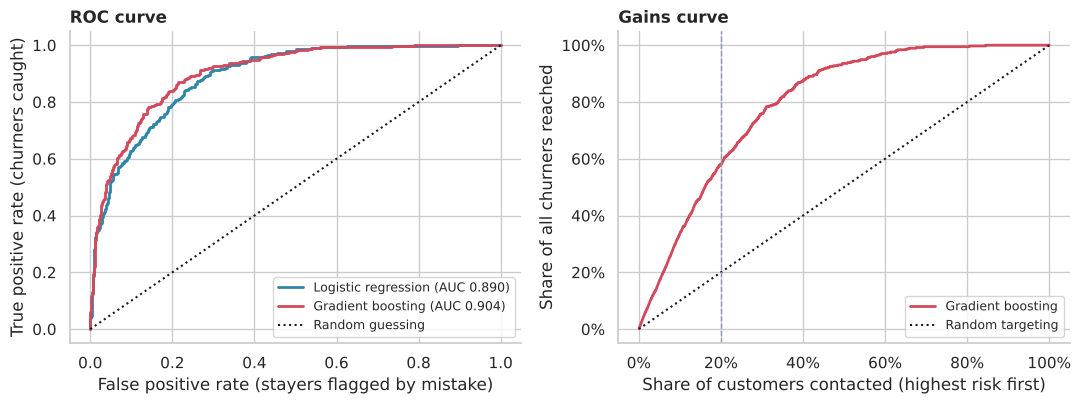

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# Left: ROC curve (closer to the top-left corner = better)
model_colors = {"Logistic regression": BLUE, "Gradient boosting": RED}
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2, color=model_colors[name], label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", label="Random guessing")
axes[0].set_xlabel("False positive rate (stayers flagged by mistake)")
axes[0].set_ylabel("True positive rate (churners caught)")
axes[0].set_title("ROC curve")
axes[0].legend(loc="lower right", fontsize=9)

# Right: gains curve (contact the riskiest customers first, how many churners do we reach?)
order = np.argsort(-p_final)
reached = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
contacted = np.arange(1, len(y_test) + 1) / len(y_test)
axes[1].plot(contacted, reached, color=RED, lw=2, label=final_name)
axes[1].plot([0, 1], [0, 1], "k:", label="Random targeting")
axes[1].axvline(0.2, color=GREY, ls="--", lw=1)
for ax in axes[1:]:
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_xlabel("Share of customers contacted (highest risk first)")
axes[1].set_ylabel("Share of all churners reached")
axes[1].set_title("Gains curve")
axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

In [22]:
# What happens if we simply say "churn" whenever the probability is 50% or more?
pred = (p_final >= 0.5).astype(int)
display(pd.DataFrame(confusion_matrix(y_test, pred),
                     index=["Actual: stayed", "Actual: churned"], columns=["Predicted: stay", "Predicted: churn"]))
print(f"Precision {precision_score(y_test, pred):.0%}  |  Recall {recall_score(y_test, pred):.0%}")

best = results.loc[final_name]
display(Markdown(f"""
**What to notice**

* The final model ({final_name}) scores ROC-AUC **{best['ROC-AUC']:.3f}** and PR-AUC **{best['PR-AUC']:.3f}** on customers it has never seen, far above the guessing values (0.50 and {y_test.mean():.2f}).
* Contacting only the **top 10%** of customers reaches **{capture_at(y_test, p_final, 0.10):.0%}** of churners, the **top 20%** reaches **{capture_at(y_test, p_final, 0.20):.0%}**, and the **top 30%** reaches **{capture_at(y_test, p_final, 0.30):.0%}**. Contacting at random would reach 10%, 20% and 30%.
* The 50% cut-off above is arbitrary. In Section 7 we choose who to contact based on **money** instead.
"""))

,Predicted: stay,Predicted: churn
Actual: stayed,934,101
Actual: churned,122,252


Precision 71%  |  Recall 67%



**What to notice**

* The final model (Gradient boosting) scores ROC-AUC **0.904** and PR-AUC **0.775** on customers it has never seen, far above the guessing values (0.50 and 0.27).
* Contacting only the **top 10%** of customers reaches **33%** of churners, the **top 20%** reaches **58%**, and the **top 30%** reaches **76%**. Contacting at random would reach 10%, 20% and 30%.
* The 50% cut-off above is arbitrary. In Section 7 we choose who to contact based on **money** instead.


## 6. Explain: what drives the predictions?

**Goal:** be able to answer "why does the model say that?" to a manager or a sceptical colleague.

**Permutation importance** is a simple, model-agnostic idea: shuffle one column so it carries no information, and measure how much the model gets worse. A big drop means the model relies heavily on that column.

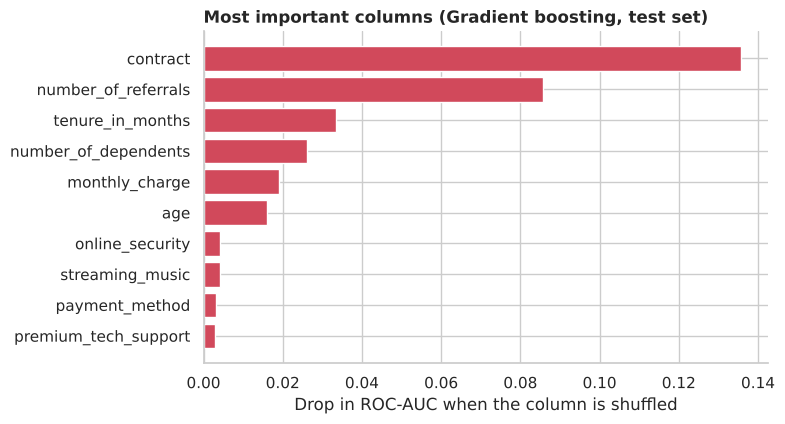


**What to notice:** the model leans most on **contract**, **number_of_referrals** and **tenure_in_months**. Compare this with the charts in Section 4: contract, referrals and tenure also showed some of the biggest gaps there. When a hand-made chart and a model point at the same columns, that is a good sign: two independent methods tell the same story.

> **Pitfall:** reading importance as cause and effect. It tells you what the *model uses*, not what *makes customers leave*. Correlated columns also share the credit between them.


In [23]:
result = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED)
importance = pd.Series(result.importances_mean, index=X_test.columns).sort_values(ascending=False)

top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(top.index, top.values, color=RED)
ax.set_xlabel("Drop in ROC-AUC when the column is shuffled")
ax.set_title(f"Most important columns ({final_name}, test set)")
plt.tight_layout()
plt.show()

top3 = importance.head(3).index.tolist()
display(Markdown(f"""
**What to notice:** the model leans most on **{top3[0]}**, **{top3[1]}** and **{top3[2]}**. Compare this with the charts in Section 4: contract, referrals and tenure also showed some of the biggest gaps there. When a hand-made chart and a model point at the same columns, that is a good sign: two independent methods tell the same story.

> **Pitfall:** reading importance as cause and effect. It tells you what the *model uses*, not what *makes customers leave*. Correlated columns also share the credit between them.
"""))

## 7. Decide: turn probabilities into money

**Goal:** decide *who to contact* by comparing the expected gain with the cost, instead of picking an arbitrary "top 20%".

**The logic.** Contacting a customer costs money. If the customer was going to leave (probability `p`), the offer saves them with some success rate, and a saved customer keeps paying for a while:

> **expected net value of contacting a customer = p × SAVE_RATE × value − COST**
> where **value = monthly charge × HORIZON months × MARGIN**

Contact exactly the customers whose expected net value is **positive**.

**The four numbers below are assumptions, not facts from the data.** In a real project you would get them from Finance and the retention team, and the sensitivity check below shows how much they matter.

In [24]:
# ---- Business assumptions (edit these and re-run!) ----
COST = 15.0        # $ per retention contact (agent time + incentive)
SAVE_RATE = 0.30   # share of would-be churners who stay after being contacted
MARGIN = 0.50      # profit margin on revenue
HORIZON = 12       # months of revenue kept when a customer is saved

test_rows = df.loc[X_test.index]
value = test_rows["monthly_charge"].clip(lower=0).to_numpy() * HORIZON * MARGIN   # negative charges floored at 0
did_churn = y_test.to_numpy()
expected_value = p_final * SAVE_RATE * value - COST

def campaign_result(name, contact):
    """What would this contact policy have earned on the test set?"""
    contact = np.asarray(contact, dtype=bool)
    retained_margin = (did_churn * SAVE_RATE * value)[contact].sum()     # only real churners can be saved
    cost = COST * contact.sum()
    return {"policy": name, "customers contacted": int(contact.sum()), "campaign cost ($)": cost,
            "retained margin ($)": retained_margin, "net profit ($)": retained_margin - cost}

policies = pd.DataFrame([
    campaign_result("Contact everyone", np.ones(len(p_final), dtype=bool)),
    campaign_result("Simple rule: all month-to-month customers", (test_rows["contract"] == "Month-to-Month").to_numpy()),
    campaign_result("Model: top 20% by risk", np.argsort(np.argsort(-p_final)) < int(0.2 * len(p_final))),
    campaign_result("Model: expected value > 0", expected_value > 0),
]).set_index("policy")
policies.style.format({"customers contacted": "{:,.0f}", "campaign cost ($)": "{:,.0f}",
                       "retained margin ($)": "{:,.0f}", "net profit ($)": "{:,.0f}"})

,customers contacted,campaign cost ($),retained margin ($),net profit ($)
policy,,,,
Contact everyone,"1,409","21,135","49,125","27,990"
Simple rule: all month-to-month customers,728,"10,920","41,789","30,869"
Model: top 20% by risk,281,"4,215","30,452","26,237"
Model: expected value > 0,620,"9,300","45,514","36,214"


In [25]:
best_profit = policies.loc["Model: expected value > 0", "net profit ($)"]
everyone_profit = policies.loc["Contact everyone", "net profit ($)"]
rule_profit = policies.loc["Simple rule: all month-to-month customers", "net profit ($)"]
top20_profit = policies.loc["Model: top 20% by risk", "net profit ($)"]
n_best = int(policies.loc["Model: expected value > 0", "customers contacted"])

display(Markdown(f"""
**What to notice**

* Contacting **only customers with a positive expected value** ({n_best} of {len(p_final):,} test customers) earns **${best_profit:,.0f}**, against ${everyone_profit:,.0f} for contacting everyone and ${rule_profit:,.0f} for the simple month-to-month rule.
* A fixed cut such as "top 20%" earns ${top20_profit:,.0f}. It ignores the economics, so it can stop too early or too late. The expected-value rule decides **how many** to contact for you.
* A model is worth more than its AUC: its value is in **who it lets you skip**.
* *Contact nobody* would earn $0, so any policy above zero is a gain.
"""))


**What to notice**

* Contacting **only customers with a positive expected value** (620 of 1,409 test customers) earns **$36,214**, against $27,990 for contacting everyone and $30,869 for the simple month-to-month rule.
* A fixed cut such as "top 20%" earns $26,237. It ignores the economics, so it can stop too early or too late. The expected-value rule decides **how many** to contact for you.
* A model is worth more than its AUC: its value is in **who it lets you skip**.
* *Contact nobody* would earn $0, so any policy above zero is a gain.


### 7.1 How fragile is the answer?

The save rate and the contact cost are the least certain inputs. Try a pessimistic and an optimistic value for each, and recompute the best policy every time.

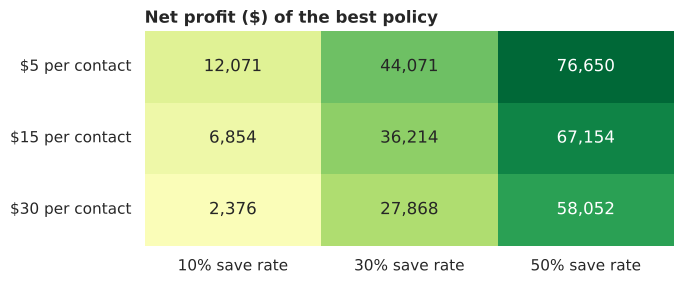


**What to notice:** the save rate moves profit far more than the contact cost does. Even in the gloomiest corner (10% save rate, $30 per contact) the best policy still earns **$2,376**, because it contacts fewer people as the economics get worse. The honest next step is a small pilot with a control group, so the real save rate replaces our 30% guess.


In [26]:
save_rates = [0.10, 0.30, 0.50]
costs = [5, 15, 30]

grid = pd.DataFrame(index=[f"${c} per contact" for c in costs], columns=[f"{s:.0%} save rate" for s in save_rates], dtype=float)
for c in costs:
    for s in save_rates:
        contact = p_final * s * value - c > 0                                   # best policy for THESE assumptions
        grid.loc[f"${c} per contact", f"{s:.0%} save rate"] = (did_churn * s * value - c)[contact].sum()

fig, ax = plt.subplots(figsize=(7, 3))
sns.heatmap(grid, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, cbar=False, ax=ax)
ax.set_title("Net profit ($) of the best policy")
plt.tight_layout()
plt.show()

worst_case = grid.iloc[-1, 0]       # lowest save rate, highest cost
display(Markdown(f"""
**What to notice:** the save rate moves profit far more than the contact cost does. Even in the gloomiest corner (10% save rate, $30 per contact) the best policy still earns **${worst_case:,.0f}**, because it contacts fewer people as the economics get worse. The honest next step is a small pilot with a control group, so the real save rate replaces our 30% guess.
"""))

### 7.2 Export a call list for the business

The last mile is a table that other tools (Excel, Power BI, Tableau) can open. One rule keeps the scores honest: every customer's probability comes from a model that **never saw that customer** (`cross_val_predict`). Scoring customers with a model trained on them would flatter the results.

We export only **active** customers (`Stayed` and `Joined`), because contacting someone who already left is not possible.

In [27]:
final_kind = MODEL_KINDS[final_name]
out_of_fold = cross_val_predict(make_model(final_kind), X, y, cv=cv, method="predict_proba")[:, 1]

scored = df[["customer_id", "customer_status", "contract", "internet_type", "tenure_in_months", "monthly_charge"]].copy()
scored["churn_probability"] = out_of_fold
scored["value_at_stake"] = scored["monthly_charge"].clip(lower=0) * HORIZON * MARGIN
scored["expected_net_value"] = scored["churn_probability"] * SAVE_RATE * scored["value_at_stake"] - COST
scored["risk_tier"] = pd.cut(scored["churn_probability"], [-0.01, 0.2, 0.5, 1.0], labels=["Low", "Medium", "High"])

active = scored[scored["customer_status"] != "Churned"].copy()
active["recommended_action"] = np.where(active["expected_net_value"] > 0, "Contact", "No action")

Path("outputs").mkdir(exist_ok=True)
active.to_csv("outputs/scored_customers.csv", index=False)

n_contact = int((active["recommended_action"] == "Contact").sum())
exp_profit = active.loc[active["recommended_action"] == "Contact", "expected_net_value"].sum()
display(Markdown(f"**{len(active):,} active customers** scored. **{n_contact:,}** are recommended for contact, with an expected net value of about "
                 f"**${exp_profit:,.0f}** under the assumptions above. Saved to `outputs/scored_customers.csv`."))

display(active["risk_tier"].value_counts().rename("active customers").to_frame().T)
active.sort_values("expected_net_value", ascending=False).head(8).round(2)

**5,174 active customers** scored. **1,525** are recommended for contact, with an expected net value of about **$56,211** under the assumptions above. Saved to `outputs/scored_customers.csv`.

risk_tier,Low,Medium,High
active customers,3860,870,444


,customer_id,customer_status,contract,internet_type,tenure_in_months,monthly_charge,churn_probability,value_at_stake,expected_net_value,risk_tier,recommended_action
4254,5995-SNNEW,Stayed,Month-to-Month,Fiber Optic,23,104.45,0.92,626.7,157.79,High,Contact
4079,5760-IFJOZ,Joined,Month-to-Month,Fiber Optic,3,107.95,0.86,647.7,151.98,High,Contact
3002,4298-OYIFC,Stayed,Month-to-Month,Fiber Optic,15,103.45,0.89,620.7,150.58,High,Contact
2323,3320-VEOYC,Stayed,Month-to-Month,Fiber Optic,14,95.60,0.92,573.6,142.94,High,Contact
2161,3096-GKWEB,Stayed,Month-to-Month,Fiber Optic,18,94.75,0.91,568.5,140.64,High,Contact
4001,5647-FXOTP,Stayed,Month-to-Month,Fiber Optic,60,105.90,0.81,635.4,139.89,High,Contact
3478,4927-WWOOZ,Joined,Month-to-Month,Fiber Optic,2,91.45,0.93,548.7,138.10,High,Contact
6082,8622-ZLFKO,Stayed,Month-to-Month,Fiber Optic,6,90.75,0.94,544.5,138.09,High,Contact


## 8. Summary and limitations

**Skill:** lead with the answer, put numbers on it, say what you are unsure of, and say what you would do next. The numbers below are calculated by the notebook, so they cannot go out of date.

In [28]:
display(Markdown(f"""
### Findings

1. **{overall:.1%} of customers churned** this quarter, taking **${lost_mrr:,.0f} of monthly revenue** with them.
2. **Contract type is the strongest lever.** Month-to-month customers churn at {rate('contract', 'Month-to-Month'):.0%}, two-year customers at {rate('contract', 'Two Year'):.0%}. The month-to-month **Fiber** group is only {hot_customer_share:.0%} of customers but **{hot_churner_share:.0%} of churners**.
3. **Risk is front-loaded.** {rate('tenure_band', '0-6'):.0%} of customers in their first six months churned, against {rate('tenure_band', '49-72'):.0%} after four years.
4. **The reasons are actionable.** Competitors drive {competitor_share:.0%} of departures (devices, offers, speed, data). Support attitude is a further, fully controllable share.
5. **The model ranks customers well.** On unseen customers: ROC-AUC **{best['ROC-AUC']:.3f}**, PR-AUC **{best['PR-AUC']:.3f}**, and the top 20% by risk contain **{best['Top-20% capture']:.0%}** of churners.
6. **A score turns into money when paired with economics.** Contacting only customers with a positive expected value nets **${best_profit:,.0f}** on the test set, versus ${everyone_profit:,.0f} for contacting everyone. {n_contact:,} active customers are currently recommended for contact.

### Recommendations

* **Move month-to-month customers onto 1-2 year contracts in months 1-6.** This is the highest-leverage fix.
* **Review the Fiber product and Offer E.** Both are over-represented among churners; compare price and performance with competitors.
* **Fix the support experience.** Coach staff on attitude and test bundling Premium Tech Support for new internet customers.
* **Run the campaign on the model's call list as an A/B test**, with a control group, to measure the *true* save rate.
"""))


### Findings

1. **26.5% of customers churned** this quarter, taking **$137,087 of monthly revenue** with them.
2. **Contract type is the strongest lever.** Month-to-month customers churn at 46%, two-year customers at 3%. The month-to-month **Fiber** group is only 27% of customers but **59% of churners**.
3. **Risk is front-loaded.** 53% of customers in their first six months churned, against 10% after four years.
4. **The reasons are actionable.** Competitors drive 45% of departures (devices, offers, speed, data). Support attitude is a further, fully controllable share.
5. **The model ranks customers well.** On unseen customers: ROC-AUC **0.904**, PR-AUC **0.775**, and the top 20% by risk contain **58%** of churners.
6. **A score turns into money when paired with economics.** Contacting only customers with a positive expected value nets **$36,214** on the test set, versus $27,990 for contacting everyone. 1,525 active customers are currently recommended for contact.

### Recommendations

* **Move month-to-month customers onto 1-2 year contracts in months 1-6.** This is the highest-leverage fix.
* **Review the Fiber product and Offer E.** Both are over-represented among churners; compare price and performance with competitors.
* **Fix the support experience.** Coach staff on attitude and test bundling Premium Tech Support for new internet customers.
* **Run the campaign on the model's call list as an A/B test**, with a control group, to measure the *true* save rate.


### Limitations (what to tell a stakeholder honestly)

* **One snapshot, not history.** Add-on services may have been recorded *at or after* the moment of churn. The model describes who *looks like* a churner. A production system should be trained on data from *before* the outcome period.
* **Correlation, not causation.** Customers choose their contract, offers and add-ons. Only a randomised experiment can show what an intervention *causes*.
* **Assumption-driven economics.** `COST`, `SAVE_RATE`, `MARGIN` and `HORIZON` are illustrative. The profit numbers show the *method*, not real profit.
* **Partial exposure.** `Joined` customers were active for only part of the quarter, so their observed churn understates a full quarter of risk.
* **Sensitive attribute and narrow scope.** `age` is used by the model, so check policy and law first. Everything is California, Q2 2022, so check for changes before reusing it on another market or period.

---

## Your turn: practice exercises

The best way to learn is to change something and watch what happens. Try these, in roughly this order of difficulty:

1. **Explore more segments.** Run `plot_churn_rates(["married", "paperless_billing", "multiple_lines"])`. Which has the biggest gap between its highest and lowest group, and is it larger or smaller than the gap for `contract`?
2. **Add a new chart.** Draw the average `monthly_charge` for churned vs retained customers. Is churn a "cheap plan" or an "expensive plan" problem?
3. **Test a feature.** Remove `"tenure_in_months"` from `FEATURES` (Section 5.1), re-run Sections 5.2 to 5.6, and compare the ROC-AUC. How much does the model depend on that one column?
4. **Stress-test the business case.** Set `COST = 40` and `SAVE_RATE = 0.10` in Section 7 and re-run. Does the best policy still make money? How many customers does it contact now?
5. **Tune a model.** In `make_model`, change `C=0.5` in the logistic regression to `0.01` and then `10`. What happens to the scores, and why might a *smaller* `C` (a stronger "keep it simple" penalty) help?

## Where to go next

This notebook is a first pass. The full version of this analysis goes further, with:

* **Survival analysis** (Kaplan-Meier curves, Cox regression): *when* do customers leave, handling those who have not left yet.
* **Statistical tests ranked by effect size**, with confidence intervals on every rate.
* **Model tuning, calibration and bootstrap comparisons**: how much to trust each probability and each difference between models.
* **Fairness checks across groups**, **customer segmentation (K-Means)** and **decision-tree rules**.
* **SHAP values** for per-customer explanations, **monitoring** and **uplift modelling** once you have A/B test results.

## Cheat sheet: terms used in this notebook

| Term | Meaning |
|---|---|
| **Churn** | A customer who left during the period (here, coded 1) |
| **Structural null** | A missing value that exists because the field does not apply (not because data was lost) |
| **Target / features** | The thing we predict (`churn`) / the columns we use to predict it |
| **Leakage** | A feature that contains the answer, or is only known after the outcome |
| **Train / test split** | Learn on one part of the data, get graded on a part the model has not seen |
| **Baseline** | A deliberately simple model that every real model must beat |
| **Pipeline** | Preprocessing + model bundled together so they are applied identically every time |
| **Cross-validation** | Repeating train/validate on several slices of the training data to check the result is stable |
| **ROC-AUC / PR-AUC** | Scores for how well the model ranks churners above stayers (higher is better) |
| **Top-20% capture** | Share of all churners found in the 20% highest-scored customers |
| **Expected value** | Probability × payoff − cost: the average result if you could repeat the decision many times |